In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler , LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [2]:
# Load the dataset 
df = pd.read_excel('Data_file3.xlsx')

df.head()

,date,country,id,active,age,alco,ap_hi,ap_lo,cholesterol,gender,gluc,height,occupation,smoke,weight,disease
0,2021-03-05 00:00:00,Indonesia,0,1,18393,0,110,80,1,2,1,168,Architect,0,62.0,0
1,2021-05-08 00:00:00,Malaysia,1,1,20228,0,140,90,3,1,1,156,Accountant,0,85.0,1
2,13-11-2022,Indonesia,2,0,18857,0,130,70,3,1,1,165,Chef,0,64.0,1
3,31-10-2018,Singapore,3,1,17623,0,150,100,1,2,1,169,Lawyer,0,82.0,1
4,25-09-2020,Singapore,4,0,17474,0,100,60,1,1,1,156,Architect,0,56.0,0


In [3]:
df.describe()

,id,active,age,alco,ap_hi,ap_lo,cholesterol,gender,gluc,height,smoke,weight,disease
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,0.803729,19468.865814,0.053771,128.817286,96.630414,1.366871,1.349571,1.226457,164.359229,0.088129,74.205690,0.499700
std,28851.302323,0.397179,2467.251667,0.225568,154.011419,188.472530,0.680250,0.476838,0.572270,8.210126,0.283484,14.395757,0.500003
min,0.000000,0.000000,10798.000000,0.000000,-150.000000,-70.000000,1.000000,1.000000,1.000000,55.000000,0.000000,10.000000,0.000000
25%,25006.750000,1.000000,17664.000000,0.000000,120.000000,80.000000,1.000000,1.000000,1.000000,159.000000,0.000000,65.000000,0.000000
50%,50001.500000,1.000000,19703.000000,0.000000,120.000000,80.000000,1.000000,1.000000,1.000000,165.000000,0.000000,72.000000,0.000000
75%,74889.250000,1.000000,21327.000000,0.000000,140.000000,90.000000,2.000000,2.000000,1.000000,170.000000,0.000000,82.000000,1.000000
max,99999.000000,1.000000,23713.000000,1.000000,16020.000000,11000.000000,3.000000,2.000000,3.000000,250.000000,1.000000,200.000000,1.000000


In [4]:
# check for missing values 

df.isnull().sum()

date           0
country        0
id             0
active         0
age            0
alco           0
ap_hi          0
ap_lo          0
cholesterol    0
gender         0
gluc           0
height         0
occupation     0
smoke          0
weight         0
disease        0
dtype: int64

In [5]:
# Ensure the column is converted to datetime
df['date'] = pd.to_datetime(df['date'], errors='coerce')

# Extract key temporal components
df['entry_year'] = df['date'].dt.year
df['entry_month'] = df['date'].dt.month
df['entry_day_of_week'] = df['date'].dt.dayofweek  # 0=Monday, 6=Sunday

# Optional: Recency/Duration feature (e.g., days elapsed since the earliest record)
df['days_since_start'] = (df['date'] - df['date'].min()).dt.days

# Now drop the original raw date column before splitting
df = df.drop(columns=['date'])

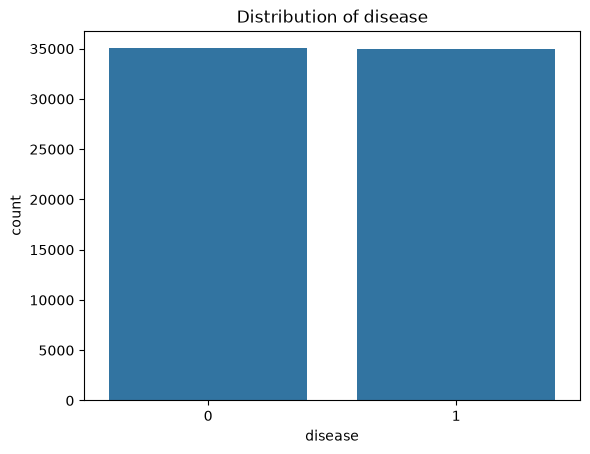

In [6]:
# Distribution of target variable

sns.countplot(x= 'disease', data = df)
plt.title('Distribution of disease')
plt.show()

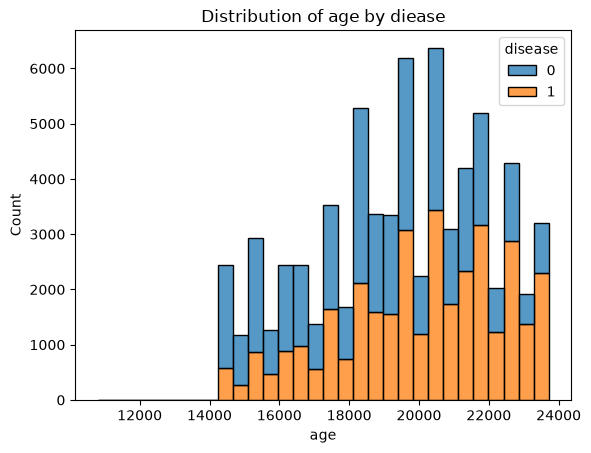

In [7]:
# Distribution of disease by age

sns.histplot(data=df, x='age', hue='disease', multiple='stack', bins=30)
plt.title('Distribution of age by diease')
plt.show()

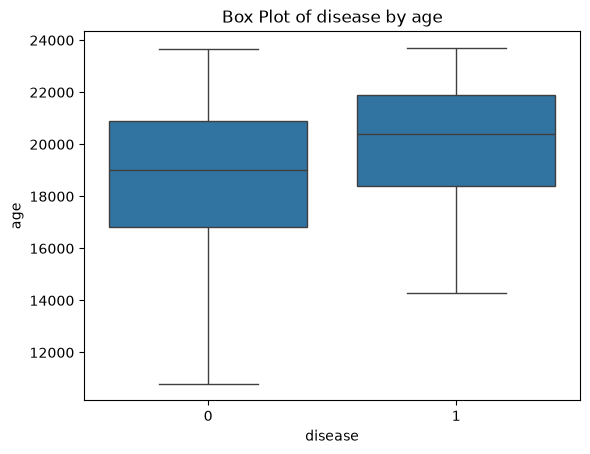

In [8]:
# Box plot for transactionAmount by fraud status

sns.boxplot(x='disease', y='age', data=df)
plt.title('Box Plot of disease by age')
plt.show()

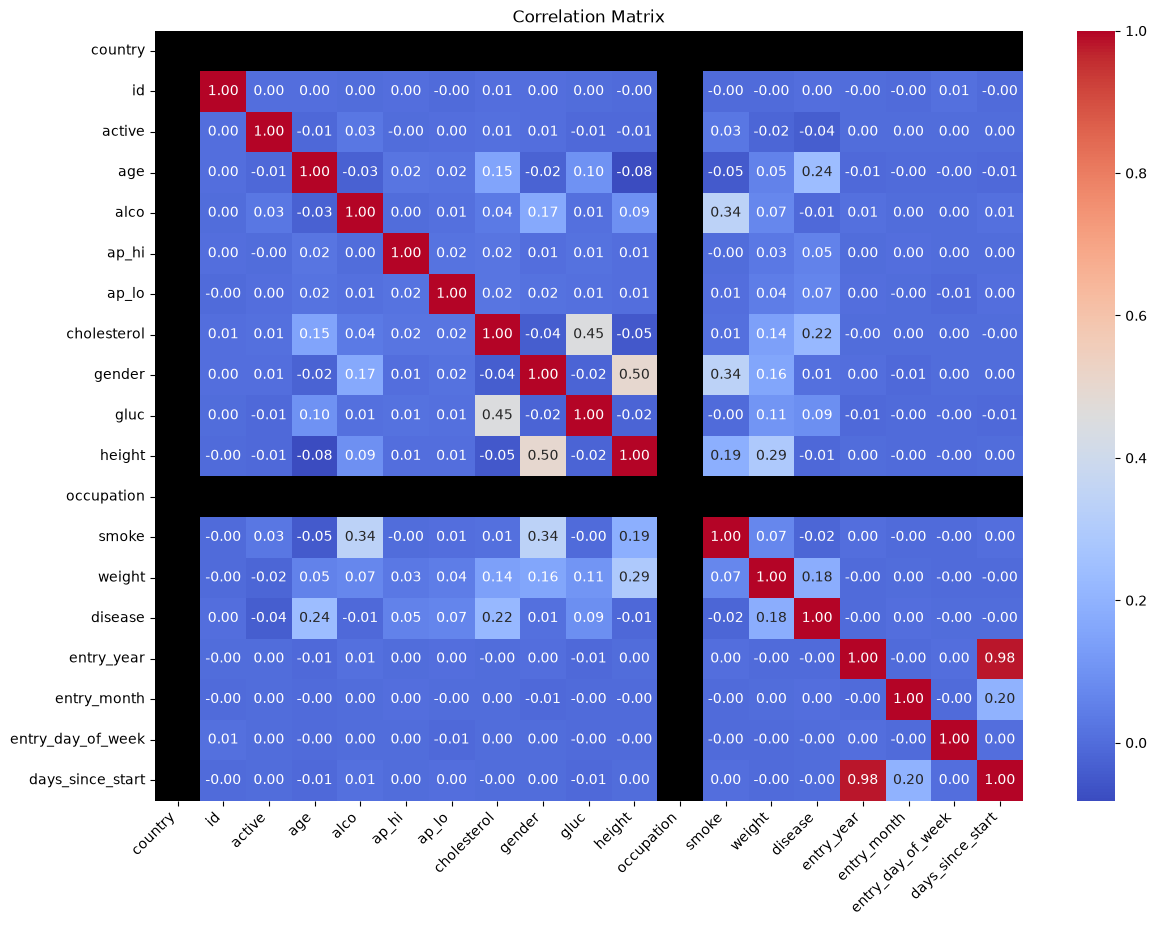

In [9]:
# Correlation Matrix

num_cols= list()

for column in df.columns:
    if df[column].dtypes != object:
        num_cols.append(column)

correlation_matrix = df[num_cols].apply(pd.to_numeric, errors='coerce').corr()
plt.figure(figsize=(14, 10))

# 2. Set axes background color to black for missing/NaN cells
ax = plt.gca()
ax.set_facecolor('black')
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm',fmt=".2f", ax=ax)
plt.xticks(rotation=45, ha='right')
plt.title('Correlation Matrix')
plt.show()

Data Preprocessing

In [10]:
num_features = ['age', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc','height', 'weight'] # replace with your num cols
cat_features = ['country', 'occupation']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
    ]
)


In [12]:
from sklearn.pipeline import Pipeline
# Features and Target (Keep raw columns intact)
X = df.drop(['id', 'disease', 'entry_day_of_week', 'entry_month'], axis=1)
y = df['disease']


from sklearn.linear_model import LogisticRegression
# 4. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

# 5. Build Pipeline
logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression())
])

# 6. Fit & Evaluate
logreg_pipeline.fit(X_train, y_train)
y_pred = logreg_pipeline.predict(X_test)

In [13]:
# Logistic Regression

# 5. Build Pipeline
logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression())
])

# 6. Fit & Evaluate
logreg_pipeline.fit(X_train, y_train)
y_pred = logreg_pipeline.predict(X_test)
logreg_accuracy = accuracy_score(y_test, y_pred)

In [14]:
# Display accuracy and performance metrics 

print(f'Logistics Regression Accuracy: {logreg_accuracy*100:.2f}')
print('\nLogistic Regression Classification Report:')
print (classification_report(y_test, y_pred))

Logistics Regression Accuracy: 71.77

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.76      0.73     10506
           1       0.74      0.68      0.71     10494

    accuracy                           0.72     21000
   macro avg       0.72      0.72      0.72     21000
weighted avg       0.72      0.72      0.72     21000



KNN Algorithm

In [15]:
from sklearn.neighbors import KNeighborsClassifier

In [16]:
# K-Nearest Neighbors
# Create a KNN pipeline using the preprocessor
knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])

# Fit and predict using the pipeline
knn_pipeline.fit(X_train, y_train)
knn_pred = knn_pipeline.predict(X_test)
knn_accuracy = accuracy_score(y_test, knn_pred)

In [17]:
# Display accuracy and performance metrics
print(f'K-Nearest Neighbors Accuracy: {knn_accuracy*100:.2f}')
print('\nK-Nearest Neighbors Classification Report:')
print(classification_report(y_test, knn_pred))

K-Nearest Neighbors Accuracy: 62.16

K-Nearest Neighbors Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.65      0.63     10506
           1       0.63      0.59      0.61     10494

    accuracy                           0.62     21000
   macro avg       0.62      0.62      0.62     21000
weighted avg       0.62      0.62      0.62     21000



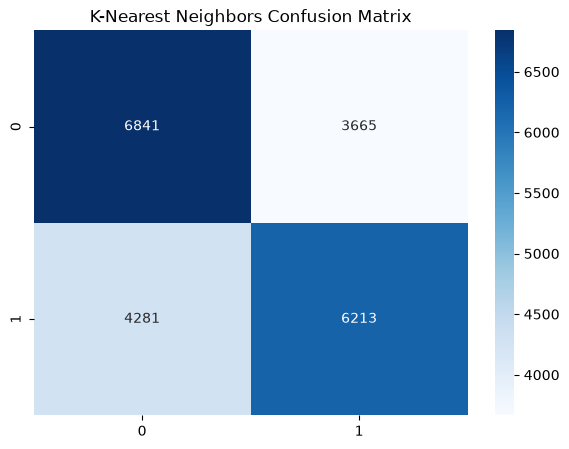

In [18]:
# Confusion Matrix
plt.figure(figsize=(7,5))
sns.heatmap(confusion_matrix(y_test, knn_pred), annot=True, fmt='d', cmap='Blues')
plt.title('K-Nearest Neighbors Confusion Matrix')
plt.show()

Decision Tree Algorithm

In [19]:
from sklearn.tree import DecisionTreeClassifier

In [20]:
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=0))
])

# Fit and predict using the pipeline
dt_pipeline.fit(X_train, y_train)
dt_pred = dt_pipeline.predict(X_test)
dt_accuracy = accuracy_score(y_test, dt_pred)

In [21]:
# Display accuracy and performance metrics

print (f'Decision Tree Accuracy :{dt_accuracy*100:.2f}')
print('\nDecision Tree Classification Report:')
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy :62.86

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.63      0.63     10506
           1       0.63      0.62      0.63     10494

    accuracy                           0.63     21000
   macro avg       0.63      0.63      0.63     21000
weighted avg       0.63      0.63      0.63     21000



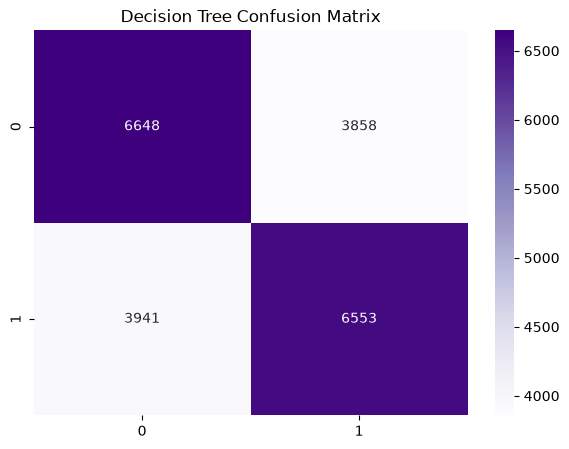

In [22]:
# Confusion Matrix

plt.figure(figsize=(7,5))
sns.heatmap(confusion_matrix(y_test, dt_pred), annot=True, fmt='d', cmap='Purples')
plt.title('Decision Tree Confusion Matrix')
plt.show()

Support Vector Machine Algorithm

In [31]:
import warnings
from sklearn.exceptions import ConvergenceWarning

# Suppress the convergence warning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

In [32]:


from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# Support Vector Machine with proper scaling to ensure convergence
svm_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),  # Your existing preprocessor
    ('scaler', StandardScaler()),  # Add explicit scaling step after preprocessing
    ('classifier', SVC(kernel='linear', random_state=0, max_iter=10000))  # Increased max_iter
])


# Fit and predict using the pipeline
svm_pipeline.fit(X_train, y_train)
svm_pred = svm_pipeline.predict(X_test)
svm_accuracy = accuracy_score(y_test, svm_pred)



In [33]:
# Display accuracy and performance metrics

print(f'Support Vector Accuracy: {svm_accuracy*100:.2f}')
print('\nSupport Vector Machine Classification Report:')
print(classification_report(y_test, svm_pred))

Support Vector Accuracy: 50.97

Support Vector Machine Classification Report:
              precision    recall  f1-score   support

           0       0.53      0.17      0.26     10506
           1       0.51      0.85      0.63     10494

    accuracy                           0.51     21000
   macro avg       0.52      0.51      0.45     21000
weighted avg       0.52      0.51      0.45     21000



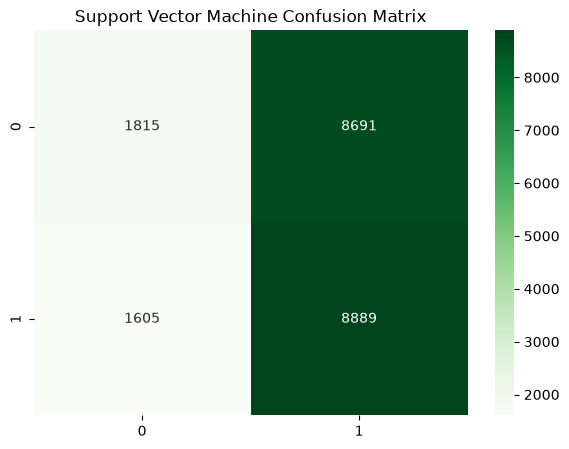

In [34]:
# Confusion Matrix

plt.figure(figsize=(7,5))
sns.heatmap(confusion_matrix(y_test, svm_pred), annot=True, fmt='d', cmap='Greens')
plt.title('Support Vector Machine Confusion Matrix')
plt.show()

Model Comparison

In [35]:
# Summary of accuracies
model_accuracies = {
    'Logistic Regression': logreg_accuracy,
    'K-Nearest Neighbors': knn_accuracy,
    'Decision Tree': dt_accuracy,
    'Support Vector Machine': svm_accuracy
}

# Display accuracies
print("--- Model Accuracy Comparison ---")
for model, accuracy in model_accuracies.items():
    print(f'{model} Accuracy: {accuracy*100:.2f}%')

--- Model Accuracy Comparison ---
Logistic Regression Accuracy: 71.77%
K-Nearest Neighbors Accuracy: 62.16%
Decision Tree Accuracy: 62.86%
Support Vector Machine Accuracy: 50.97%


In [36]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [None, 5, 10],
    'classifier__min_samples_split': [2, 5]
}

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

grid_search = GridSearchCV(rf_pipeline, param_grid, cv=cv, scoring='recall', n_jobs=-1)
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [None, 5, ...], 'classifier__min_samples_split': [2, 5], 'classifier__n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Suppor

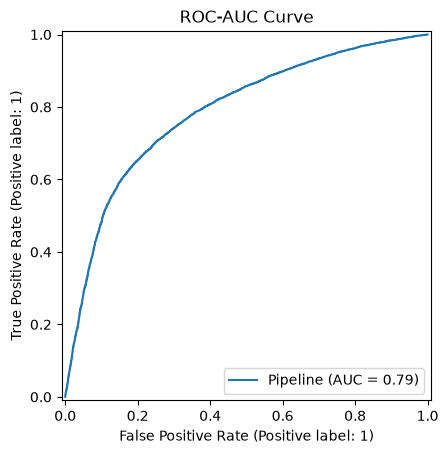

In [37]:
from sklearn.metrics import RocCurveDisplay, classification_report

RocCurveDisplay.from_estimator(grid_search.best_estimator_, X_test, y_test)
plt.title('ROC-AUC Curve')
plt.show()

In [ ]:
!pip install shap

import shap

# 1. Extract the fitted preprocessor and classifier from your pipeline
preprocessor = logreg_pipeline.named_steps['preprocessor']
classifier = logreg_pipeline.named_steps['classifier']

# 2. Transform X_test into fully numerical data using the preprocessor
X_test_transformed = preprocessor.transform(X_test)

# 3. Retrieve feature names generated by ColumnTransformer (including One-Hot Encoded categories)
feature_names = preprocessor.get_feature_names_out()

# 4. Convert transformed numpy array back to a Pandas DataFrame with proper feature names
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=feature_names)

# Use all 21,000 samples for the background dataset
masker = shap.maskers.Independent(X_test_transformed_df, max_samples=21000)

# 5. Initialize and compute SHAP values using the classifier and transformed numerical DataFrame
explainer = shap.Explainer(classifier, masker=masker)
shap_values = explainer(X_test_transformed_df)

shap.summary_plot(shap_values, X_test_transformed_df)

In [ ]:
import joblib

# Save the fitted pipeline (includes both preprocessor and model)
joblib.dump(logreg_pipeline, 'Heart_Disease_Model.pkl')